# EcoTransformer: Transformer construido y entrenado desde cero para dar retroalimentación

La CNN (notebook 01) dice **qué residuos hay**. Este Transformer **toma esa respuesta** (y una pregunta opcional del usuario) y **genera la retroalimentación** en español: en qué caneca va cada residuo, si es orgánico o inorgánico y cómo prepararlo.

```
CNN:          plástico ×2, vidrio ×1
                    │
Entrada:      "det plastico 2 vidrio 1 sep que hago con esto"
                    │
              ┌─────────────┐      ┌─────────────┐
              │ CODIFICADOR │ ───► │DECODIFICADOR│ ──► "Plástico (2): es inorgánico, va en la caneca blanca. ..."
              └─────────────┘      └─────────────┘
```

Se implementa **desde cero** la arquitectura de *"Attention is All You Need"* (2017) vista en clase: tokenizador propio, embeddings, codificación posicional, **atención multi-cabeza programada a mano** y una arquitectura **codificador-decodificador**, como la de los modelos de traducción. Los pesos parten de valores aleatorios; no se usa ningún modelo pre-entrenado.

$$\text{Attention}(Q,K,V)=\text{softmax}\left(\frac{QK^T}{\sqrt{d_k}}\right)V$$

In [1]:
import sys, os, time, random
sys.path.insert(0, os.path.abspath('..'))
import numpy as np, torch, torch.nn as nn, matplotlib.pyplot as plt, seaborn as sns
from config import TRANSFORMER_PESOS, OUTPUTS
from src.retro_datos import generar, entrada, retro_general
from src.transformer import EcoTransformer, Vocabulario, tokenizar, PAD, SOS, EOS, UNK
import inspect, src.transformer as T

torch.manual_seed(0); random.seed(0); np.random.seed(0)
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print('Dispositivo:', device)

Dispositivo: cuda


## 1. La atención, programada a mano
Este es el núcleo del Transformer (archivo `src/transformer.py`):

In [2]:
print(inspect.getsource(T.AtencionMultiCabeza.forward))

    def forward(self, q, k, v, mascara=None):
        B = q.size(0)
        # 1) Proyecciones lineales y separación en h cabezas: (B, h, L, d_k)
        Q = self.W_q(q).view(B, -1, self.h, self.d_k).transpose(1, 2)
        K = self.W_k(k).view(B, -1, self.h, self.d_k).transpose(1, 2)
        V = self.W_v(v).view(B, -1, self.h, self.d_k).transpose(1, 2)
        # 2) Puntajes de atención: Q·Kᵀ / √d_k
        puntajes = Q @ K.transpose(-2, -1) / math.sqrt(self.d_k)
        if mascara is not None:
            puntajes = puntajes.masked_fill(~mascara, float("-inf"))
        # 3) softmax -> distribución de probabilidad sobre las posiciones
        A = torch.softmax(puntajes, dim=-1)
        self.pesos_atencion = A.detach()
        # 4) Suma ponderada de los valores y unión de cabezas
        salida = (self.dropout(A) @ V).transpose(1, 2).contiguous().view(B, -1, self.h * self.d_k)
        return self.W_o(salida)



## 2. Dataset propio de retroalimentación
No existe un dataset público para esta tarea, así que lo **creamos nosotros** (`src/retro_datos.py`) a partir de las normas de separación de la Resolución 2184 de 2019. Hay tres tipos de ejemplos:

| Tipo | Entrada | Salida |
|---|---|---|
| Retroalimentación general | Lo detectado por la CNN (+ "dame recomendaciones") | Una línea por material con caneca, tipo y cómo prepararlo, más un cierre |
| Pregunta por material | "¿dónde boto una lata de atún?" | Consejo para ese material |
| Pregunta de conocimiento | "¿qué hago con el vidrio roto?", pilas, compost… | Respuesta de la base de conocimiento |

Las preguntas se generan con plantillas, sinónimos, saludos y cortesías. **Las 2 últimas plantillas de cada tipo nunca se usan en el entrenamiento**: se reservan para medir si el modelo entiende frases nuevas.

In [3]:
train = generar(40000, semilla=1)
val = generar(2000, semilla=2)
test_vistas = generar(2000, semilla=3)                     # plantillas vistas, combinaciones nuevas
test_nuevas = generar(2000, semilla=4, reservadas=True)    # plantillas NUNCA vistas
print(f'train {len(train)} | val {len(val)} | test (vistas) {len(test_vistas)} | test (nuevas) {len(test_nuevas)}')
for a, b in train[:4]: print(f'\nENTRADA: {a}\nSALIDA:  {b}')

train 40000 | val 2000 | test (vistas) 2000 | test (nuevas) 2000

ENTRADA: det carton 2 sep disculpa a donde va una revista
SALIDA:  El papel es inorgánico y va en la caneca blanca . Debe estar limpio y seco ; el papel con grasa va en la negra .

ENTRADA: det carton 22 sep que debo hacer con lo detectado porfa
SALIDA:  Cartón ( 22 ) : es inorgánico , va en la caneca blanca . Desármalo y aplánalo . Todo es aprovechable : llévalo limpio y seco a la caneca blanca .

ENTRADA: det vidrio 5 metal 1 sep
SALIDA:  Vidrio ( 5 ) : es inorgánico , va en la caneca blanca . Vacío , sin tapa y con cuidado . Metal ( 1 ) : es inorgánico , va en la caneca blanca . Enjuaga las latas y aplástalas . Todo es aprovechable : llévalo limpio y seco a la caneca blanca .

ENTRADA: det ninguno sep como reciclo el periodico gracias
SALIDA:  El papel es inorgánico y va en la caneca blanca . Debe estar limpio y seco ; el papel con grasa va en la negra .


## 3. Tokenizador propio
Tokenización por palabras (como vimos en clase): cada palabra y cada signo de puntuación es un token. Se crean dos vocabularios: uno para la entrada (sin tildes, en minúsculas) y otro para la salida.

In [4]:
v_src = Vocabulario.construir([a for a, _ in train])
v_tgt = Vocabulario.construir([b for _, b in train])
print('Vocabulario entrada:', len(v_src), '| Vocabulario salida:', len(v_tgt))
ej = train[0][0]
print('\nTexto :', ej); print('Tokens:', tokenizar(ej)); print('IDs   :', v_src.codificar(ej))

Vocabulario entrada: 204 | Vocabulario salida: 267

Texto : det carton 2 sep disculpa a donde va una revista
Tokens: ['det', 'carton', '2', 'sep', 'disculpa', 'a', 'donde', 'va', 'una', 'revista']
IDs   : [82, 63, 15, 172, 87, 34, 88, 192, 188, 167]


In [5]:
def a_tensor(pares):
    S = [torch.tensor(v_src.codificar(a)) for a, _ in pares]
    Tg = [torch.tensor(v_tgt.codificar(b, extremos=True)) for _, b in pares]
    S = nn.utils.rnn.pad_sequence(S, batch_first=True, padding_value=PAD)
    Tg = nn.utils.rnn.pad_sequence(Tg, batch_first=True, padding_value=PAD)
    return S, Tg

datos = {k: a_tensor(v) for k, v in dict(train=train, val=val, test_vistas=test_vistas, test_nuevas=test_nuevas).items()}
print({k: (tuple(s.shape), tuple(t.shape)) for k, (s, t) in datos.items()})

{'train': ((40000, 26), (40000, 134)), 'val': ((2000, 24), (2000, 134)), 'test_vistas': ((2000, 25), (2000, 134)), 'test_nuevas': ((2000, 25), (2000, 134))}


## 4. Modelo (pesos aleatorios)

In [6]:
HP = dict(d_modelo=128, n_cabezas=4, n_capas=3, d_ff=512, dropout=0.1)
modelo = EcoTransformer(len(v_src), len(v_tgt), **HP).to(device)
n = sum(p.numel() for p in modelo.parameters())
print(f'Parámetros: {n:,} — 3 capas de codificador + 3 de decodificador, 4 cabezas de atención, d_modelo=128')

Parámetros: 1,483,787 — 3 capas de codificador + 3 de decodificador, 4 cabezas de atención, d_modelo=128


## 5. Entrenamiento
Se usa *teacher forcing*: el decodificador recibe la respuesta correcta desplazada una posición y aprende a predecir la siguiente palabra. La pérdida es la entropía cruzada sobre el vocabulario (sin contar el relleno `<pad>`).

In [7]:
EPOCAS, LOTE = 14, 128
S_tr, T_tr = datos['train']
criterio = nn.CrossEntropyLoss(ignore_index=PAD, label_smoothing=0.05)
optim = torch.optim.AdamW(modelo.parameters(), lr=1e-3, betas=(0.9, 0.98), weight_decay=0.01)
pasos = EPOCAS * (len(S_tr) // LOTE)
sched = torch.optim.lr_scheduler.OneCycleLR(optim, max_lr=1e-3, total_steps=pasos, pct_start=0.1)

@torch.no_grad()
def perdida_y_acc(S, Tg):
    modelo.eval(); tot, ok, n_tok, perd = 0, 0, 0, 0
    for i in range(0, len(S), 256):
        s, t = S[i:i+256].to(device), Tg[i:i+256].to(device)
        out = modelo(s, t[:, :-1]); y = t[:, 1:]
        perd += criterio(out.reshape(-1, out.size(-1)), y.reshape(-1)).item() * len(s); tot += len(s)
        m = y != PAD; ok += ((out.argmax(-1) == y) & m).sum().item(); n_tok += m.sum().item()
    return perd / tot, ok / n_tok

hist, t0 = [], time.time()
for ep in range(1, EPOCAS + 1):
    modelo.train(); perm = torch.randperm(len(S_tr)); perd, nb = 0, 0
    for i in range(0, len(S_tr) - LOTE + 1, LOTE):
        idx = perm[i:i+LOTE]; s, t = S_tr[idx].to(device), T_tr[idx].to(device)
        out = modelo(s, t[:, :-1])
        loss = criterio(out.reshape(-1, out.size(-1)), t[:, 1:].reshape(-1))
        optim.zero_grad(set_to_none=True); loss.backward()
        nn.utils.clip_grad_norm_(modelo.parameters(), 1.0); optim.step(); sched.step()
        perd += loss.item(); nb += 1
    vl, va = perdida_y_acc(*datos['val'])
    hist.append(dict(epoca=ep, train_loss=perd/nb, val_loss=vl, val_acc=va))
    print(f'Época {ep:2d} | pérdida train {perd/nb:.4f} | pérdida val {vl:.4f} | accuracy por token (val) {va:.4f}')
print(f'\nTiempo de entrenamiento: {(time.time()-t0)/60:.1f} min')
torch.save({'modelo': modelo.state_dict(), 'vocab_src': v_src.itos, 'vocab_tgt': v_tgt.itos, 'hparams': HP}, TRANSFORMER_PESOS)
print('Guardado en', TRANSFORMER_PESOS)

Época  1 | pérdida train 2.3420 | pérdida val 0.6094 | accuracy por token (val) 0.9725


Época  2 | pérdida train 0.5237 | pérdida val 0.4970 | accuracy por token (val) 0.9999


Época  3 | pérdida train 0.4877 | pérdida val 0.4870 | accuracy por token (val) 1.0000


Época  4 | pérdida train 0.4831 | pérdida val 0.4843 | accuracy por token (val) 0.9999


Época  5 | pérdida train 0.4813 | pérdida val 0.4820 | accuracy por token (val) 0.9999


Época  6 | pérdida train 0.4803 | pérdida val 0.4809 | accuracy por token (val) 1.0000


... (4 outputs left out)

Época 11 | pérdida train 0.4786 | pérdida val 0.4791 | accuracy por token (val) 1.0000


Época 12 | pérdida train 0.4785 | pérdida val 0.4790 | accuracy por token (val) 1.0000


Época 13 | pérdida train 0.4785 | pérdida val 0.4789 | accuracy por token (val) 1.0000


Época 14 | pérdida train 0.4784 | pérdida val 0.4789 | accuracy por token (val) 1.0000

Tiempo de entrenamiento: 6.4 min
Guardado en C:\Users\DANILO MONTEZUMA\Desktop\Folders\8vo\SistemasIA\FINAL\models\ecotransformer.pt


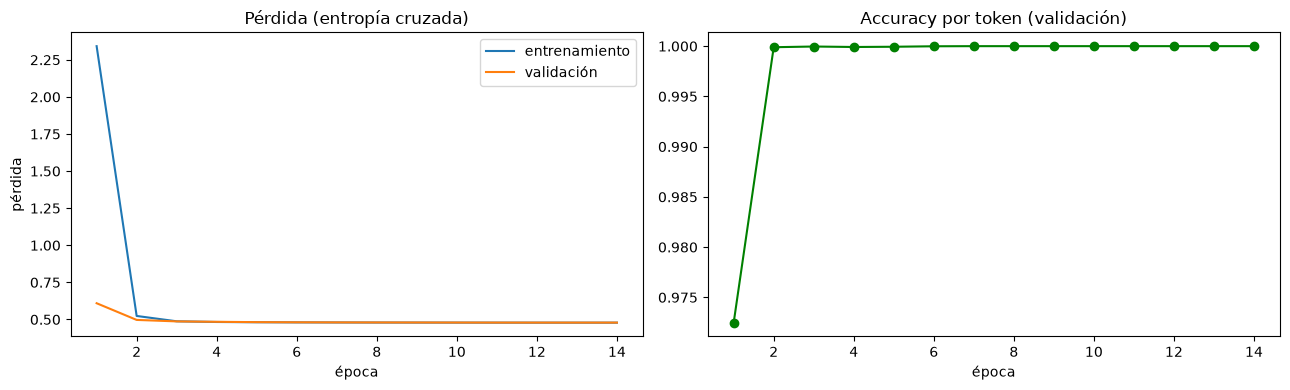

In [8]:
ep = [h['epoca'] for h in hist]
fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 4))
a1.plot(ep, [h['train_loss'] for h in hist], label='entrenamiento'); a1.plot(ep, [h['val_loss'] for h in hist], label='validación')
a1.set_xlabel('época'); a1.set_ylabel('pérdida'); a1.set_title('Pérdida (entropía cruzada)'); a1.legend()
a2.plot(ep, [h['val_acc'] for h in hist], 'o-', color='green'); a2.set_xlabel('época'); a2.set_title('Accuracy por token (validación)')
plt.tight_layout(); plt.savefig(OUTPUTS / 'curvas_transformer.png', dpi=120); plt.show()

## 6. Evaluación: generación completa
Ahora el modelo genera la respuesta él solo, palabra por palabra (sin *teacher forcing*). Se mide:
- **Coincidencia exacta:** la respuesta generada es idéntica a la esperada.
- **Canecas correctas:** todas las canecas mencionadas en la respuesta esperada aparecen en la generada (lo más importante para el usuario).

In [9]:
import re
def generar_lote(pares):
    S, _ = a_tensor(pares); res = []
    for i in range(0, len(S), 256):
        out = modelo.generar(S[i:i+256].to(device)).tolist()
        for ids in out:
            ids = ids[:ids.index(EOS)] if EOS in ids else ids
            res.append(v_tgt.decodificar(ids))
    return res

def canecas(t): return sorted(re.findall(r'caneca (blanca|verde|negra)', t.lower()))
modelo.eval(); resultados = {}
for nombre in ['test_vistas', 'test_nuevas']:
    pares = test_vistas if nombre == 'test_vistas' else test_nuevas
    gen = generar_lote(pares)
    esperado = [T.destokenizar(tokenizar(b)) for _, b in pares]
    exacta = np.mean([g == e for g, e in zip(gen, esperado)])
    can = np.mean([set(canecas(e)) <= set(canecas(g)) for g, e in zip(gen, esperado)])
    resultados[nombre] = (exacta, can, gen, esperado)
    print(f'{nombre:12s} | coincidencia exacta: {exacta:.3f} | canecas correctas: {can:.3f}')

test_vistas  | coincidencia exacta: 1.000 | canecas correctas: 1.000


test_nuevas  | coincidencia exacta: 0.745 | canecas correctas: 0.887


### Ejemplos con frases nunca vistas en el entrenamiento

In [10]:
_, _, gen, esp = resultados['test_nuevas']
for i in range(8):
    print(f'ENTRADA : {test_nuevas[i][0]}')
    print(f'GENERADO: {gen[i]}')
    print('OK' if gen[i] == esp[i] else f'ESPERADO: {esp[i]}'); print()

ENTRADA : det carton 10 sep disculpa como separo un tubo de carton gracias
GENERADO: El cartón es inorgánico y va en la caneca blanca. Desármalo y aplánalo; si tiene comida va en la negra.
OK

ENTRADA : det organico 26 carton 18 vidrio 5 metal 2 plastico 1 sep hola dame retroalimentacion
GENERADO: Orgánico (26): va en la caneca verde. Sirve para hacer compost. Cartón (18): es inorgánico, va en la caneca blanca. Desármalo y aplánalo. Vidrio (5): es inorgánico, va en la caneca blanca. Vacío, sin tapa y con cuidado. Metal (2): es inorgánico, va en la caneca blanca. Enjuaga las latas y aplástalas. Plástico (1): es inorgánico, va en la caneca blanca. Vacíalo, enjuágalo y aplástalo. Recuerda: orgánicos a la caneca verde e inorgánicos limpios y secos a la blanca.
OK

ENTRADA : det vidrio 21 sep una pregunta explicame organico e inorganico porfa
GENERADO: Los residuos orgánicos vienen de seres vivos y se descomponen rápido, como la comida y las cáscaras. Los inorgánicos son materiales fabricad

## 7. Prueba conectada con la CNN

In [11]:
casos = [({'plastico': 3, 'organico': 1}, ''), ({'vidrio': 2}, 'dame recomendaciones'), ({'metal': 1, 'papel': 2}, 'en que caneca va esto'),
         ({}, ''), ({'carton': 1}, 'se me rompio un vaso de vidrio que hago'), ({'organico': 4}, 'como hago compost')]
for conteo, preg in casos:
    s = torch.tensor([v_src.codificar(entrada(conteo, preg))], device=device)
    ids = modelo.generar(s)[0].tolist(); ids = ids[:ids.index(EOS)] if EOS in ids else ids
    print(f'CNN: {conteo} | pregunta: "{preg}"\n→ {v_tgt.decodificar(ids)}\n')

CNN: {'plastico': 3, 'organico': 1} | pregunta: ""
→ Plástico (3): es inorgánico, va en la caneca blanca. Vacíalo, enjuágalo y aplástalo. Orgánico (1): va en la caneca verde. Sirve para hacer compost. Recuerda: orgánicos a la caneca verde e inorgánicos limpios y secos a la blanca.



CNN: {'vidrio': 2} | pregunta: "dame recomendaciones"
→ Vidrio (2): es inorgánico, va en la caneca blanca. Vacío, sin tapa y con cuidado. Todo es aprovechable: llévalo limpio y seco a la caneca blanca.



CNN: {'metal': 1, 'papel': 2} | pregunta: "en que caneca va esto"
→ Papel (2): es inorgánico, va en la caneca blanca. Debe estar limpio y seco. Metal (1): es inorgánico, va en la caneca blanca. Enjuaga las latas y aplástalas. Todo es aprovechable: llévalo limpio y seco a la caneca blanca.

CNN: {} | pregunta: ""
→ No se detectaron residuos. Acerca el objeto a la cámara o analiza otra imagen.



CNN: {'carton': 1} | pregunta: "se me rompio un vaso de vidrio que hago"
→ El vidrio roto no se aplasta ni se lava a mano. Recoge los trozos con escoba, envuélvelos en papel periódico o en una caja, marca el paquete como vidrio roto y deposítalo en la caneca blanca.



CNN: {'organico': 4} | pregunta: "como hago compost"
→ Para hacer compost alterna capas de residuos verdes (cáscaras, restos de fruta, cuncho de café) y secos (hojas secas, cartón sin tinta). Mantén la mezcla húmeda y revuélvela cada semana. En dos o tres meses tendrás abono.



## 8. ¿A qué le presta atención el decodificador?
Mapa de la **atención cruzada** de la última capa (promedio de las 4 cabezas): para cada palabra generada (filas), qué tokens de la entrada mira (columnas). Se ve cómo, al escribir cada material y su cantidad, el modelo mira el token correspondiente de la salida de la CNN.

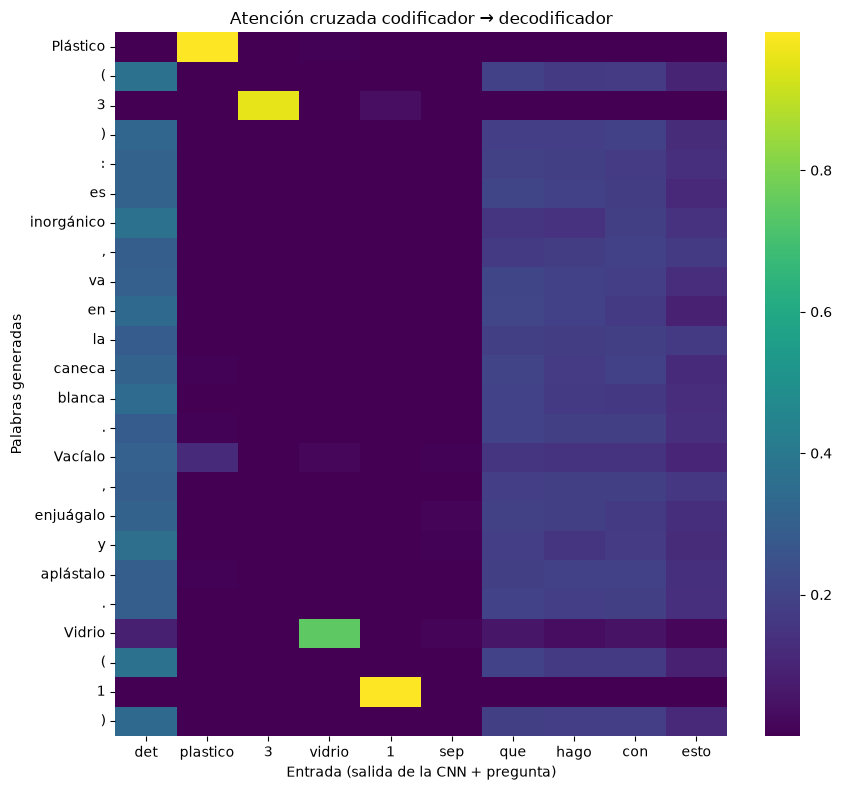

In [12]:
conteo = {'plastico': 3, 'vidrio': 1}
x = entrada(conteo, 'que hago con esto')
s = torch.tensor([v_src.codificar(x)], device=device)
ids = modelo.generar(s)[0].tolist(); ids = ids[:ids.index(EOS)] if EOS in ids else ids
t = torch.tensor([[SOS] + ids], device=device)
with torch.no_grad(): modelo(s, t)
A = modelo.decodificador[-1].atencion_cruzada.pesos_atencion[0].mean(0).cpu().numpy()[:len(ids)]
fil = [v_tgt.itos[i] for i in ids][:24]; col = tokenizar(x)
plt.figure(figsize=(9, 8))
sns.heatmap(A[:24], xticklabels=col, yticklabels=fil, cmap='viridis')
plt.xlabel('Entrada (salida de la CNN + pregunta)'); plt.ylabel('Palabras generadas')
plt.title('Atención cruzada codificador → decodificador'); plt.tight_layout()
plt.savefig(OUTPUTS / 'atencion_transformer.png', dpi=120); plt.show()